In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import keras
from keras.models import Sequential
from keras.layers import Dense, Flatten

In [51]:
df = pd.read_csv("Final_Retail_Sales.csv")

print(df.head())
print(df.shape)

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156  2017-11-08  2017-11-11    Second Class    CG-12520   
1       2  CA-2017-152156  2017-11-08  2017-11-11    Second Class    CG-12520   
2       3  CA-2017-138688  2017-06-12  2017-06-16    Second Class    DV-13045   
3       4  US-2016-108966  2016-10-11  2016-10-18  Standard Class    SO-20335   
4       5  US-2016-108966  2016-10-11  2016-10-18  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

          Category  Sub-Category  \
0        Furniture     Bookcases   
1        Furniture  

In [52]:
X = df[["Category", "Sub-Category", "Segment", "Region", "Ship Mode", "Quantity", "Discount"]].copy()
y = df["Sales Level"].copy()
print(y.value_counts())

Sales Level
Regular    8832
High       1162
Name: count, dtype: int64


In [53]:
for col in X.select_dtypes(include="object").columns:
    encoder = LabelEncoder()
    X[col] = encoder.fit_transform(X[col].astype(str))

target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y.astype(str))

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 7995
Testing rows: 1999


In [55]:
dt = DecisionTreeClassifier(max_depth=10, random_state=42)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 88.84 %


In [56]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 88.64 %


In [57]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

KNN Accuracy: 88.84 %


In [58]:
model = Sequential()
model.add(Dense(12, input_dim=X_train.shape[1], activation='relu'))
model.add(Dense(24, activation='relu'))
model.add(Dense(5, activation='relu'))
model.add(Dense(len(np.unique(y_train)), activation='softmax'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 12)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 24)             │           312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 5)              │           125 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 2)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545 (2.13 KB)

 Trainable params: 545 (2.13 KB)

 Non-trainable params: 0 (0.00 B)

In [59]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='SGD', metrics=['accuracy'])

In [60]:
history = model.fit(X_train, y_train, epochs=50, batch_size=64, validation_data=(X_test, y_test))

Epoch 1/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8438 - loss: 0.5362 - val_accuracy: 0.8839 - val_loss: 0.4325
Epoch 2/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8837 - loss: 0.4011 - val_accuracy: 0.8839 - val_loss: 0.3851
Epoch 3/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8837 - loss: 0.3771 - val_accuracy: 0.8839 - val_loss: 0.3743
Epoch 4/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8837 - loss: 0.3695 - val_accuracy: 0.8839 - val_loss: 0.3686
Epoch 5/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8837 - loss: 0.3648 - val_accuracy: 0.8839 - val_loss: 0.3643
Epoch 6/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8837 - loss: 0.3611 - val_accuracy: 0.8839 - val_loss: 0.3609
Epoch 7/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8837 - loss: 0.3581 - val_accuracy: 0.8839 - val_loss: 0.3580
Epoch 8/50
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8837 - loss: 0.3555 - val_accuracy: 0.

In [61]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Neural Network Accuracy:", round(test_accuracy * 100, 2), "%")
print("Neural Network Loss:", round(test_loss, 4))

Neural Network Accuracy: 88.44 %
Neural Network Loss: 0.3136


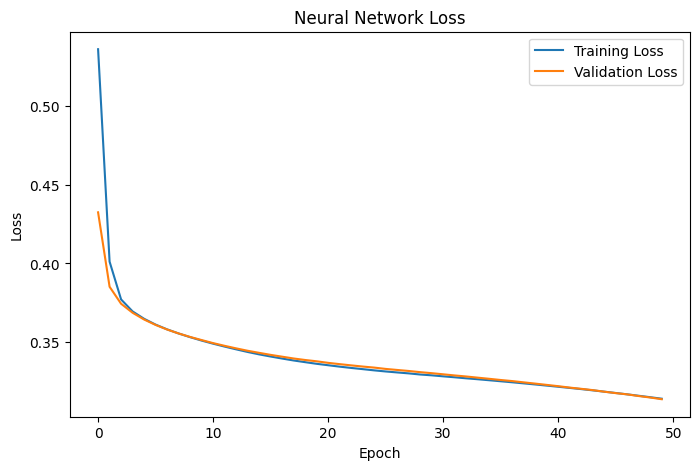

In [62]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Neural Network Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

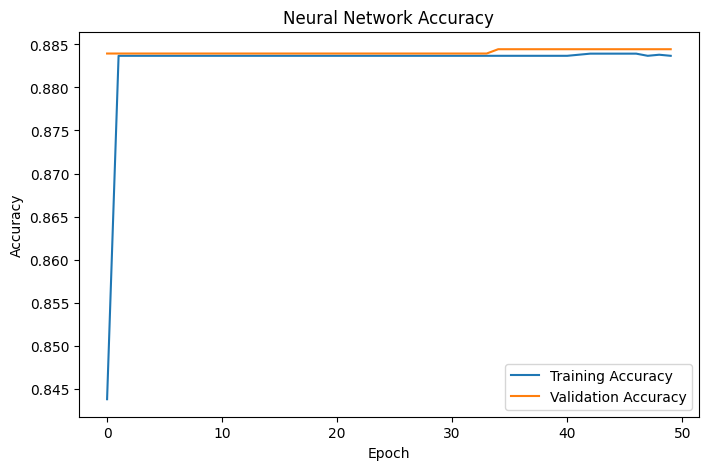

In [63]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [64]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "Neural Network"
    ],
    "Accuracy": [dt_accuracy, rf_accuracy, knn_accuracy, test_accuracy]
})

results = results.sort_values(by="Accuracy", ascending=False)

print(results)

            Model  Accuracy
0   Decision Tree  0.888444
2             KNN  0.888444
1   Random Forest  0.886443
3  Neural Network  0.884442


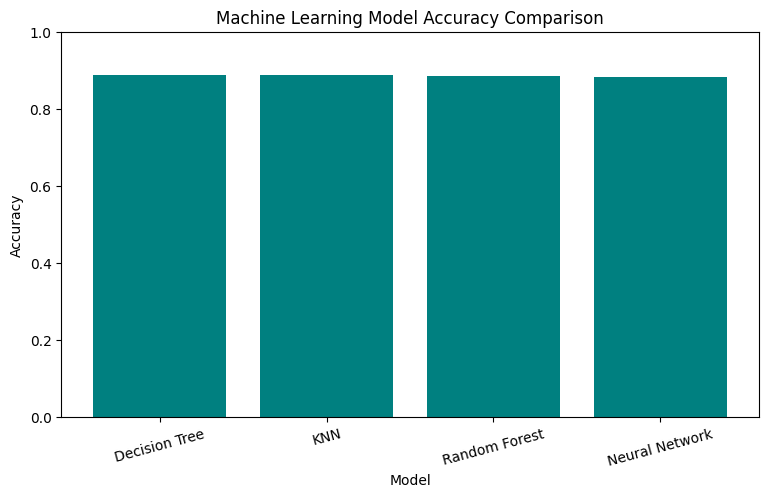

In [65]:
plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["Accuracy"], color="teal")
plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

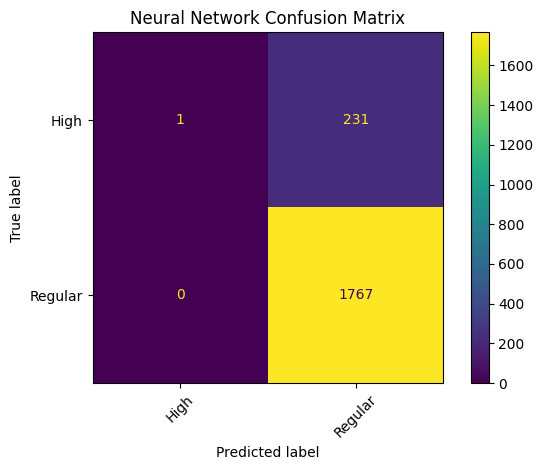

In [66]:
nn_predictions = np.argmax(model.predict(X_test, verbose=0), axis=1)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    nn_predictions,
    display_labels=target_encoder.classes_,
    xticks_rotation=45
)

plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()